<a href="https://colab.research.google.com/github/FhmiKh19/Uji-Validitas-dan-Reliabitas/blob/main/uji_validitas_reliabilitas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Uji Validitas dan Reliabilitas Instrumen Kuesioner
Data: kelas **3 TI A** (n = 39). Mengikuti tahapan *Modul Pengujian Validitas dan Reliabilitas Instrumen*, dijalankan offline.

In [15]:
import re
import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

NAMA_FILE = "data3TIA.xlsx"
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)

## Langkah 3: Membaca data dan memisahkan butir

In [16]:
JUMLAH_KOLOM_DEMOGRAFI = 6   # Timestamp, Score, Kelas, Jenis Kelamin, 2 kolom jumlah platform AI

df = pd.read_excel(NAMA_FILE)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
# Kolom "Durasi (jam) ... gadget" bukan butir Likert (tidak berformat Dimensi [pernyataan])
# dan terselip di tengah butir, sehingga dikeluarkan dari analisis.
non_likert = [c for c in butir.columns if "[" not in c]
butir = butir.drop(columns=non_likert)

print("Kelas            :", df["Kelas"].unique())
print("Jumlah responden :", len(df))
print("Kolom non-Likert dikeluarkan:", non_likert)
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Kelas            : ['3 TI A']
Jumlah responden : 39
Kolom non-Likert dikeluarkan: ['Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan ']
Jumlah butir     : 29
Data kosong      : 0


## Langkah 4: Mengubah jawaban Likert menjadi angka

In [17]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.apply(lambda s: s.astype(str).str.strip().map(skala)).apply(pd.to_numeric, errors="coerce")
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))

Sel yang gagal dikonversi: 0


## Langkah 5: Mengelompokkan butir per dimensi (+ kode butir)

In [18]:
KODE = {
    "Penggunaan AI pada tugas atau projek kuliah": "PAI",
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": "APS",
    "Kebiasaan penggunaan teknologi digital": "KTD",
    "Prokrastinasi akademik.": "PRA",
    "Rsspon emosional": "REM",
}
NAMA_BAKU = {  # penulisan nama dimensi yang dirapikan untuk laporan
    "PAI": "Penggunaan AI pada Tugas atau Proyek Kuliah",
    "APS": "Aspek Psikologis Penggunaan AI pada Tugas atau Proyek Kuliah",
    "KTD": "Kebiasaan Penggunaan Teknologi Digital",
    "PRA": "Prokrastinasi Akademik",
    "REM": "Respon Emosional",
}
dimensi, kode_butir, teks_butir = {}, {}, {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?)\s*\[", kolom).group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)
for nama, daftar in dimensi.items():
    for i, kolom in enumerate(daftar, 1):
        kode_butir[kolom] = f"{KODE[nama]}{i}"
        teks_butir[kolom] = re.search(r"\[(.*)\]", kolom).group(1).strip()
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik.: 4 butir
Rsspon emosional: 5 butir


## Fungsi uji

In [19]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (alpha=0,05; df={n-2}) = {r_tabel:.3f}")


def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))


def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")


def uji(dim):
    """Langkah 6 & 7: validitas dan reliabilitas untuk dict dimensi -> kolom."""
    val, rel = [], []
    for nama, daftar in dim.items():
        x = num[daftar]
        total = x.sum(axis=1)
        a = cronbach_alpha(x)
        rel.append({"Kode": KODE[nama], "Dimensi": NAMA_BAKU[KODE[nama]],
                    "Jumlah butir": len(daftar), "Cronbach's alpha": round(a, 3),
                    "Kategori": kategori(a)})
        for kolom in daftar:
            r, p = stats.pearsonr(x[kolom], total)
            rk, _ = stats.pearsonr(x[kolom], total - x[kolom])
            a_del = round(cronbach_alpha(x.drop(columns=kolom)), 3) if len(daftar) > 2 else np.nan
            val.append({
                "Dimensi": NAMA_BAKU[KODE[nama]],
                "Kode": kode_butir[kolom],
                "Butir": teks_butir[kolom],
                "r hitung": round(r, 3),
                "r tabel": round(r_tabel, 3),
                "Corrected r": round(rk, 3),
                "p-value": round(p, 4),
                "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
                "Alpha dimensi": round(a, 3),
                "Alpha jika dihapus": a_del,
            })
    return pd.DataFrame(val), pd.DataFrame(rel)


def keputusan(row):
    """Pedoman pengambilan keputusan (Modul bagian 6)."""
    valid = row["Keterangan"] == "Valid"
    naik = row["Alpha jika dihapus"] > row["Alpha dimensi"]
    if valid and not naik:
        return "Pertahankan"
    if not valid and naik:
        return "Buang/revisi, uji ulang"
    if valid and naik:
        return "Tinjau isi butir"
    return "Tinjau ulang (validitas isi)"

n = 39 | r tabel (alpha=0,05; df=37) = 0.316


## Putaran 1: seluruh butir

In [20]:
tabel_validitas, tabel_reliabilitas = uji(dimensi)
tabel_validitas["Keputusan"] = tabel_validitas.apply(keputusan, axis=1)
pd.set_option("display.width", 250, "display.max_colwidth", 40)
print("\n=== VALIDITAS (putaran 1) ===")
print(tabel_validitas.drop(columns=["Butir", "Dimensi"]).to_string(index=False))
print("\n=== RELIABILITAS (putaran 1) ===")
print(tabel_reliabilitas.to_string(index=False))


=== VALIDITAS (putaran 1) ===
Kode  r hitung  r tabel  Corrected r  p-value  Keterangan  Alpha dimensi  Alpha jika dihapus                    Keputusan
PAI1     0.525    0.316        0.277   0.0006       Valid          0.370               0.275                  Pertahankan
PAI2     0.269    0.316        0.105   0.0972 Tidak valid          0.370               0.362 Tinjau ulang (validitas isi)
PAI3     0.643    0.316        0.379   0.0000       Valid          0.370               0.193                  Pertahankan
PAI4     0.669    0.316        0.397   0.0000       Valid          0.370               0.171                  Pertahankan
PAI5     0.515    0.316        0.126   0.0008       Valid          0.370               0.367                  Pertahankan
PAI6     0.455    0.316        0.139   0.0036       Valid          0.370               0.348                  Pertahankan
PAI7     0.016    0.316       -0.247   0.9237 Tidak valid          0.370               0.513      Buang/revisi, uji

## Uji ulang iteratif: buang butir tidak valid, ulangi hingga semua valid

In [21]:
dim_akhir = {k: list(v) for k, v in dimensi.items()}
riwayat = []
putaran = 1
while True:
    v, r = uji(dim_akhir)
    tidak_valid = v[v["Keterangan"] == "Tidak valid"]
    if tidak_valid.empty:
        break
    putaran += 1
    for _, row in tidak_valid.iterrows():
        for nama, daftar in dim_akhir.items():
            for kolom in list(daftar):
                if kode_butir[kolom] == row["Kode"]:
                    daftar.remove(kolom)
                    riwayat.append({"Putaran": putaran, "Butir dibuang": row["Kode"],
                                    "r hitung": row["r hitung"]})
tabel_val_akhir, tabel_rel_akhir = v, r
banding = tabel_reliabilitas[["Kode", "Dimensi", "Jumlah butir", "Cronbach's alpha", "Kategori"]].merge(
    tabel_rel_akhir[["Kode", "Jumlah butir", "Cronbach's alpha", "Kategori"]],
    on="Kode", suffixes=(" awal", " akhir"))
print("\n=== Butir dibuang (uji ulang) ===")
print(pd.DataFrame(riwayat).to_string(index=False) if riwayat else "Tidak ada")
print("\n=== Perbandingan alpha awal vs akhir ===")
print(banding.to_string(index=False))


=== Butir dibuang (uji ulang) ===
 Putaran Butir dibuang  r hitung
       2          PAI2     0.269
       2          PAI7     0.016
       2          APS6     0.129
       2          APS7     0.127
       2          KTD5     0.285

=== Perbandingan alpha awal vs akhir ===
Kode                                                      Dimensi  Jumlah butir awal  Cronbach's alpha awal  Kategori awal  Jumlah butir akhir  Cronbach's alpha akhir Kategori akhir
 PAI                  Penggunaan AI pada Tugas atau Proyek Kuliah                  7                  0.370 Tidak reliabel                   5                   0.530 Tidak reliabel
 APS Aspek Psikologis Penggunaan AI pada Tugas atau Proyek Kuliah                  7                  0.375 Tidak reliabel                   5                   0.668 Tidak reliabel
 KTD                       Kebiasaan Penggunaan Teknologi Digital                  6                  0.478 Tidak reliabel                   5                   0.551 Tidak reliab

## Perbandingan kriteria: r hitung > r tabel vs corrected r >= 0,30

In [22]:
n_valid_r = int((tabel_validitas["r hitung"] > r_tabel).sum())
n_valid_cr = int((tabel_validitas["Corrected r"] >= 0.30).sum())
print(f"\nValid (r hitung > r tabel) : {n_valid_r}/{len(tabel_validitas)}")
print(f"Valid (corrected r >= 0,30): {n_valid_cr}/{len(tabel_validitas)}")


Valid (r hitung > r tabel) : 24/29
Valid (corrected r >= 0,30): 13/29


## Analisis deskriptif per butir dan per dimensi

In [23]:
desk_butir, desk_dim, komposisi = [], [], []
label = ["STS", "TS", "N", "S", "SS"]
for nama, daftar in dimensi.items():
    kd = KODE[nama]
    for kolom in daftar:
        s = num[kolom]
        desk_butir.append({"Dimensi": NAMA_BAKU[kd], "Kode": kode_butir[kolom],
                           "Mean": round(s.mean(), 3), "SD": round(s.std(ddof=1), 3),
                           "Skewness": round(stats.skew(s, bias=False), 3),
                           "Kurtosis": round(stats.kurtosis(s, bias=False), 3)})
        frek = s.value_counts().reindex(range(1, 6), fill_value=0)
        komposisi.append({"Kode": kode_butir[kolom], **{l: int(f) for l, f in zip(label, frek)}})
    tot = num[daftar].sum(axis=1)
    rata = num[daftar].mean(axis=1)
    semua = num[daftar].values.ravel()
    persen = pd.Series(semua).value_counts(normalize=True).reindex(range(1, 6), fill_value=0) * 100
    desk_dim.append({"Kode": kd, "Dimensi": NAMA_BAKU[kd],
                     "Mean skor rata-rata": round(rata.mean(), 3),
                     "SD skor rata-rata": round(rata.std(ddof=1), 3),
                     "Mean skor total": round(tot.mean(), 3),
                     "SD skor total": round(tot.std(ddof=1), 3),
                     "Skewness": round(stats.skew(tot, bias=False), 3),
                     "Kurtosis": round(stats.kurtosis(tot, bias=False), 3),
                     "Min": int(tot.min()), "Maks": int(tot.max()),
                     **{f"% {l}": round(p, 1) for l, p in zip(label, persen)}})
tabel_desk_butir = pd.DataFrame(desk_butir)
tabel_desk_dim = pd.DataFrame(desk_dim)
tabel_komposisi = pd.DataFrame(komposisi)
print("\n=== DESKRIPTIF DIMENSI ===")
print(tabel_desk_dim.to_string(index=False))
print("\n=== DESKRIPTIF BUTIR ===")
print(tabel_desk_butir.drop(columns="Dimensi").to_string(index=False))


=== DESKRIPTIF DIMENSI ===
Kode                                                      Dimensi  Mean skor rata-rata  SD skor rata-rata  Mean skor total  SD skor total  Skewness  Kurtosis  Min  Maks  % STS  % TS  % N  % S  % SS
 PAI                  Penggunaan AI pada Tugas atau Proyek Kuliah                3.897              0.431           27.282          3.017    -0.425     1.612   19    34    3.7  11.4 11.4 38.8  34.8
 APS Aspek Psikologis Penggunaan AI pada Tugas atau Proyek Kuliah                3.132              0.534           21.923          3.737     0.248    -0.752   15    30   10.3  28.2 19.0 23.1  19.4
 KTD                       Kebiasaan Penggunaan Teknologi Digital                2.782              0.620           16.692          3.722    -0.255    -0.212    8    24   18.8  30.3 18.4 18.8  13.7
 PRA                                       Prokrastinasi Akademik                2.763              1.016           11.051          4.065     0.236    -0.553    4    19   14.1  35.

## Grafik komposisi jawaban per dimensi (stacked bar 100%)

In [24]:
warna = ["#c0392b", "#e67e22", "#bdc3c7", "#5dade2", "#1f618d"]
for nama, daftar in dimensi.items():
    kd = KODE[nama]
    kom = tabel_komposisi[tabel_komposisi["Kode"].str.startswith(kd)].set_index("Kode")
    pct = kom.div(kom.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(pct) + 1.6))
    left = np.zeros(len(pct))
    for l, w in zip(label, warna):
        ax.barh(pct.index, pct[l], left=left, color=w, label=l, edgecolor="white")
        for j, (val, lf) in enumerate(zip(pct[l], left)):
            if val >= 7:
                ax.text(lf + val / 2, j, f"{val:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if l in ("STS", "SS") else "black")
        left += pct[l].values
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persentase responden (%)")
    ax.set_title(f"Komposisi Jawaban - {NAMA_BAKU[kd]} (n={n})", fontsize=10)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22 if len(pct) < 6 else -0.15),
              frameon=False, fontsize=8)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/komposisi_{kd}.png", dpi=200)
    plt.close(fig)

# Histogram skor total per dimensi
fig, axes = plt.subplots(1, len(dimensi), figsize=(15, 3))
for ax, (nama, daftar) in zip(axes, dimensi.items()):
    tot = num[daftar].sum(axis=1)
    ax.hist(tot, bins=range(int(tot.min()), int(tot.max()) + 2), color="#2e86c1", edgecolor="white")
    ax.set_title(KODE[nama])
    ax.set_xlabel("Skor total")
axes[0].set_ylabel("Frekuensi")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/histogram_skor_total.png", dpi=200)
plt.close(fig)

## Langkah 8: Simpan seluruh hasil

In [25]:
daftar_butir = pd.DataFrame([{"Kode": kode_butir[k], "Dimensi": NAMA_BAKU[KODE[d]], "Butir": teks_butir[k]}
                             for d, v in dimensi.items() for k in v])
with pd.ExcelWriter(f"{OUT_DIR}/hasil_uji_validitas_reliabilitas.xlsx") as w:
    daftar_butir.to_excel(w, sheet_name="Daftar Butir", index=False)
    tabel_validitas.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    pd.DataFrame(riwayat or [{"Putaran": "-", "Butir dibuang": "Tidak ada", "r hitung": "-"}]).to_excel(
        w, sheet_name="Uji Ulang", index=False)
    banding.to_excel(w, sheet_name="Alpha Awal vs Akhir", index=False)
    tabel_desk_dim.to_excel(w, sheet_name="Deskriptif Dimensi", index=False)
    tabel_desk_butir.to_excel(w, sheet_name="Deskriptif Butir", index=False)
    tabel_komposisi.to_excel(w, sheet_name="Frekuensi Jawaban", index=False)
    num.rename(columns=kode_butir).to_excel(w, sheet_name="Data Numerik", index=False)
print(f"\nHasil disimpan di {OUT_DIR}/")


Hasil disimpan di output/


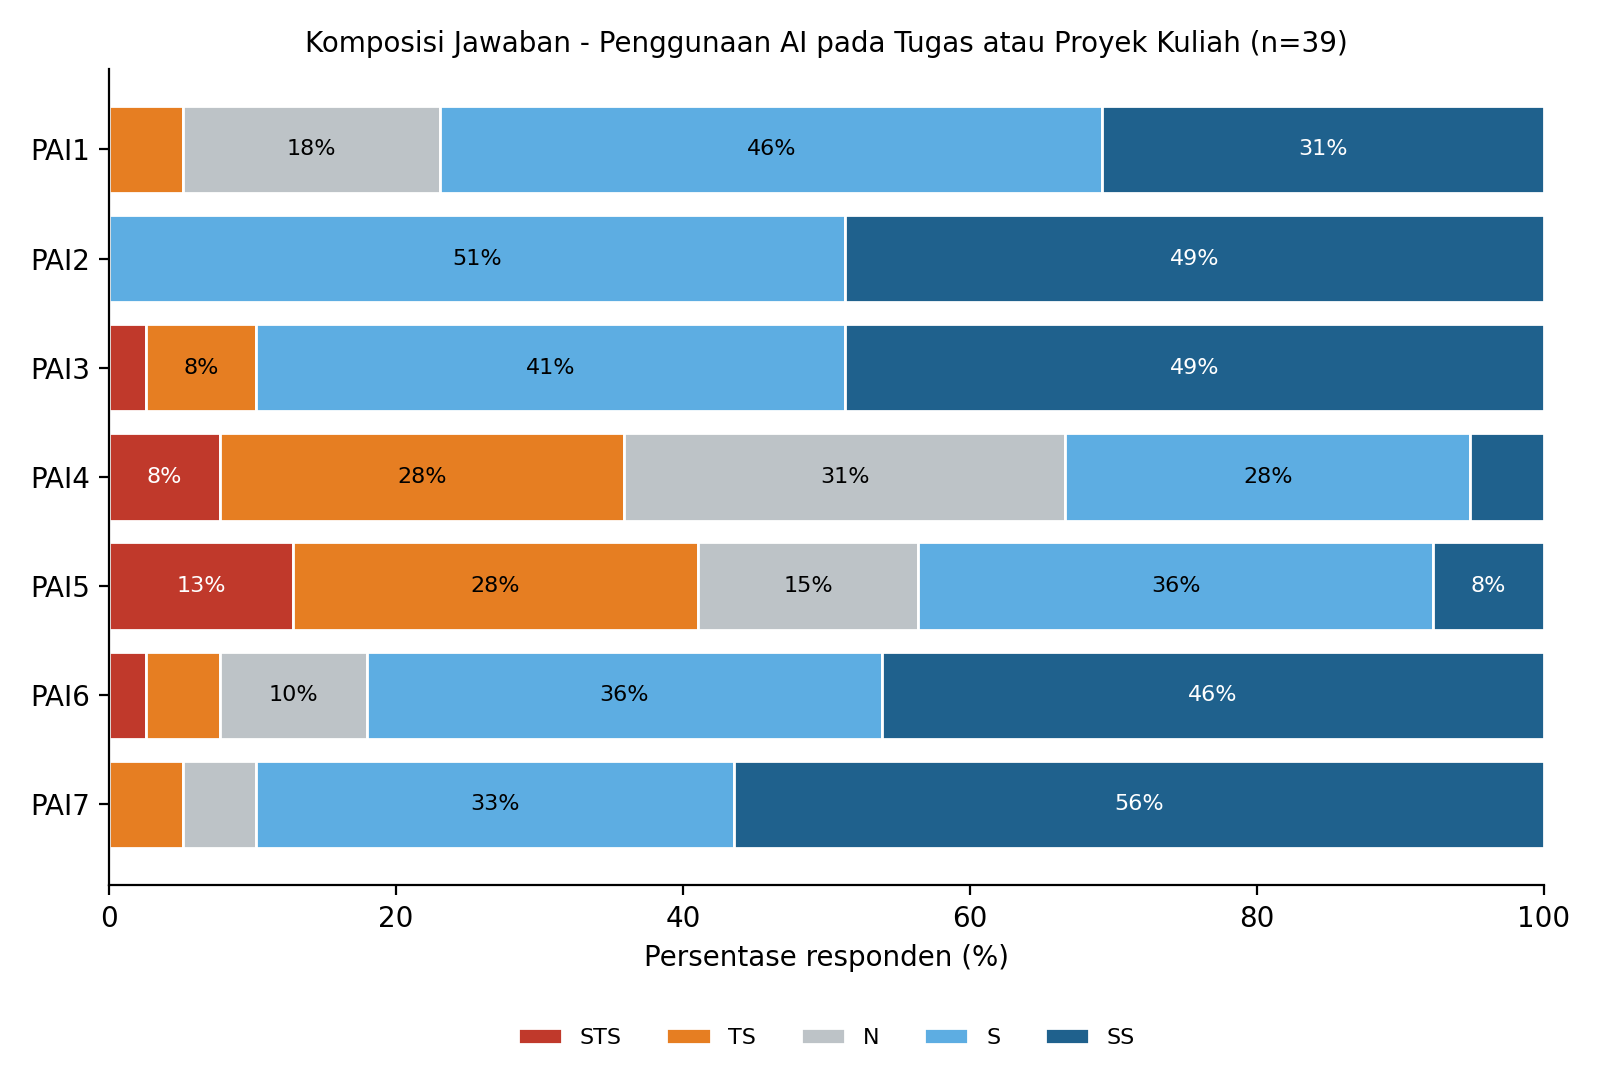

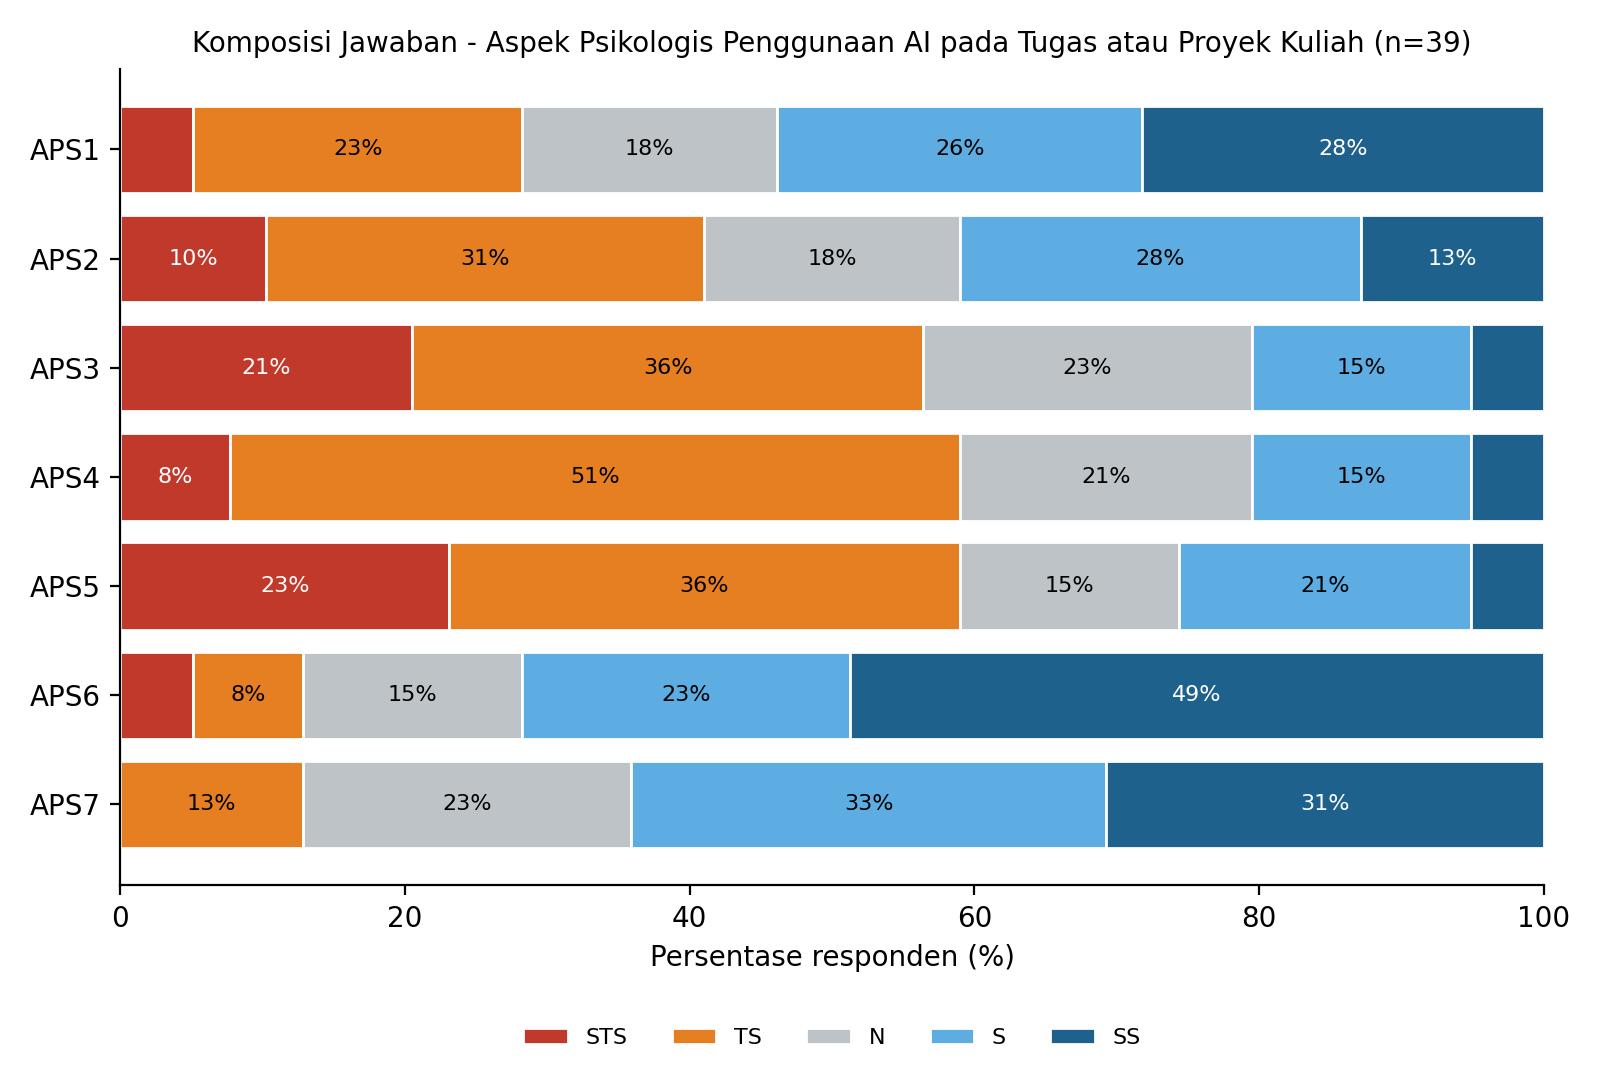

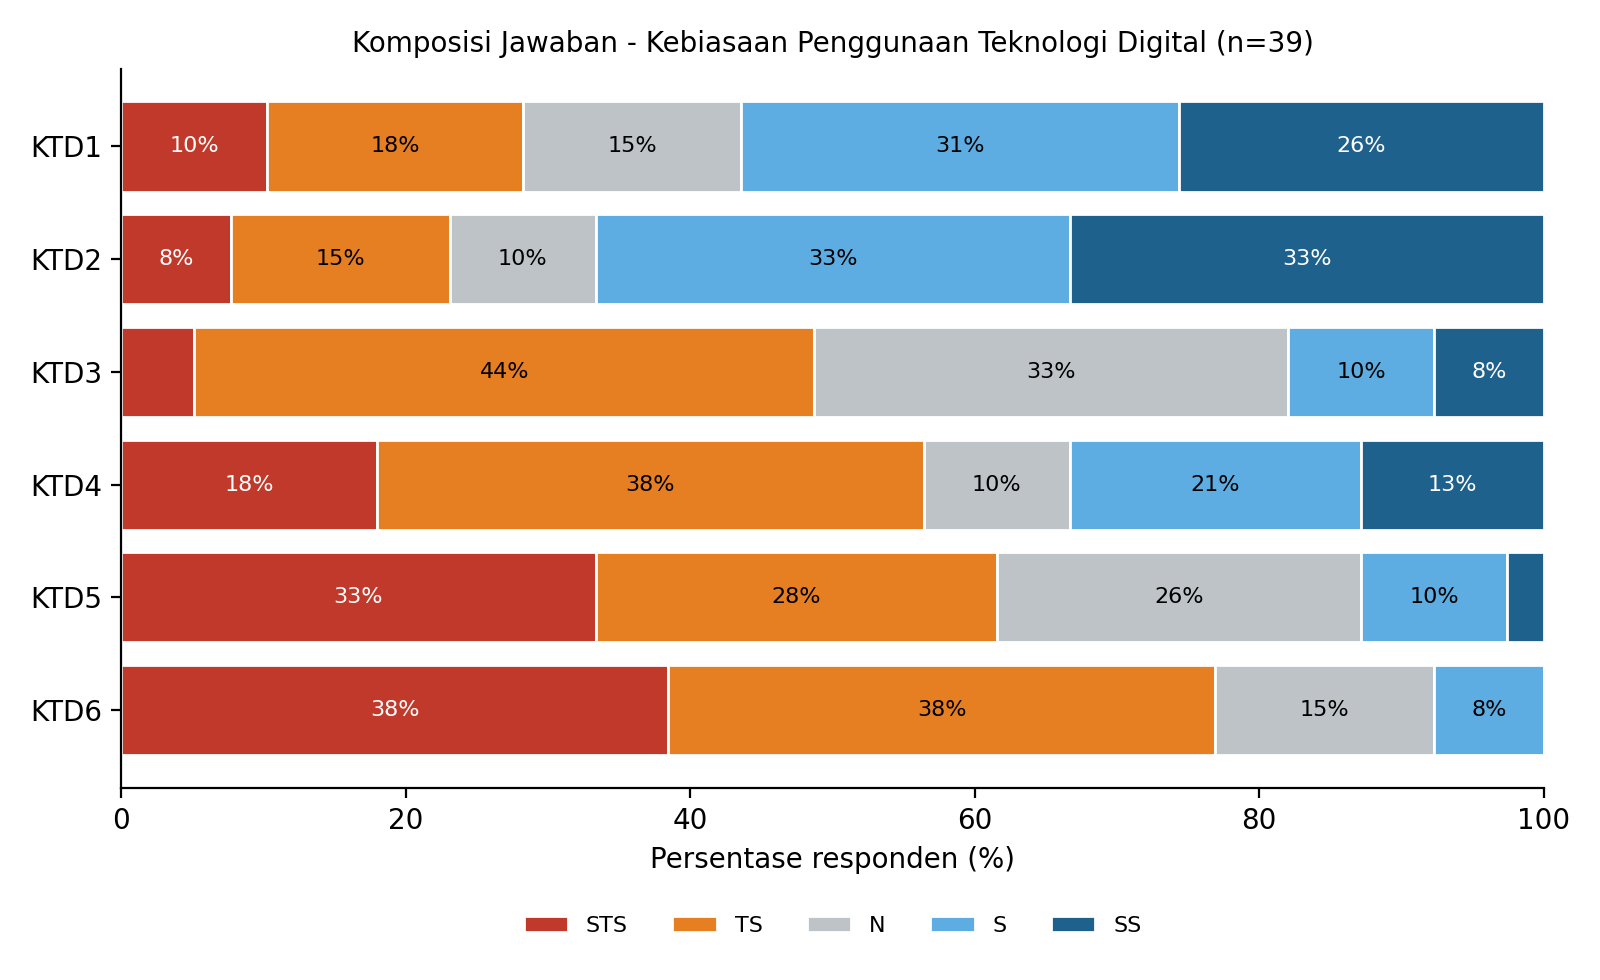

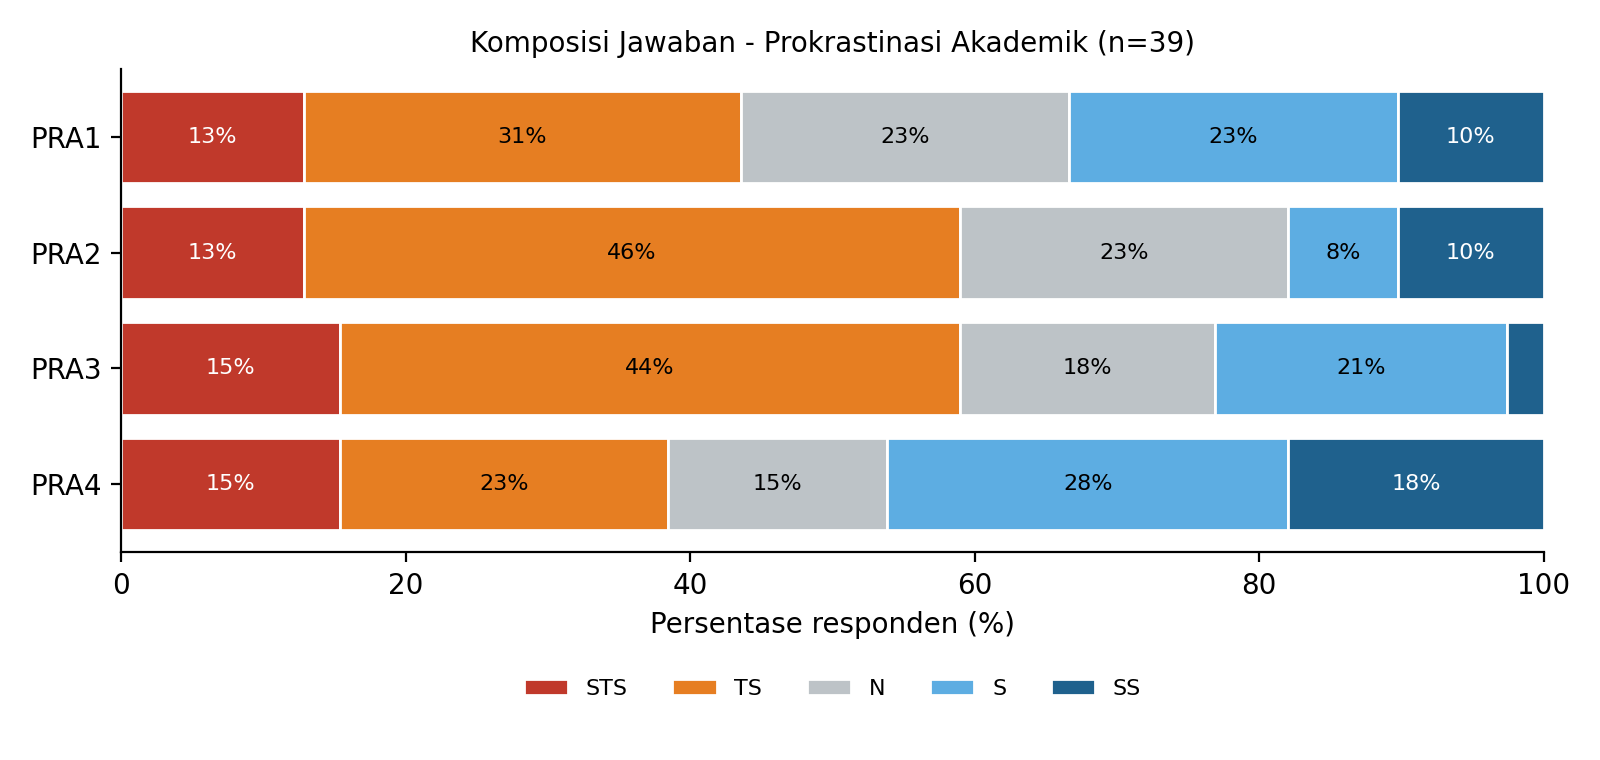

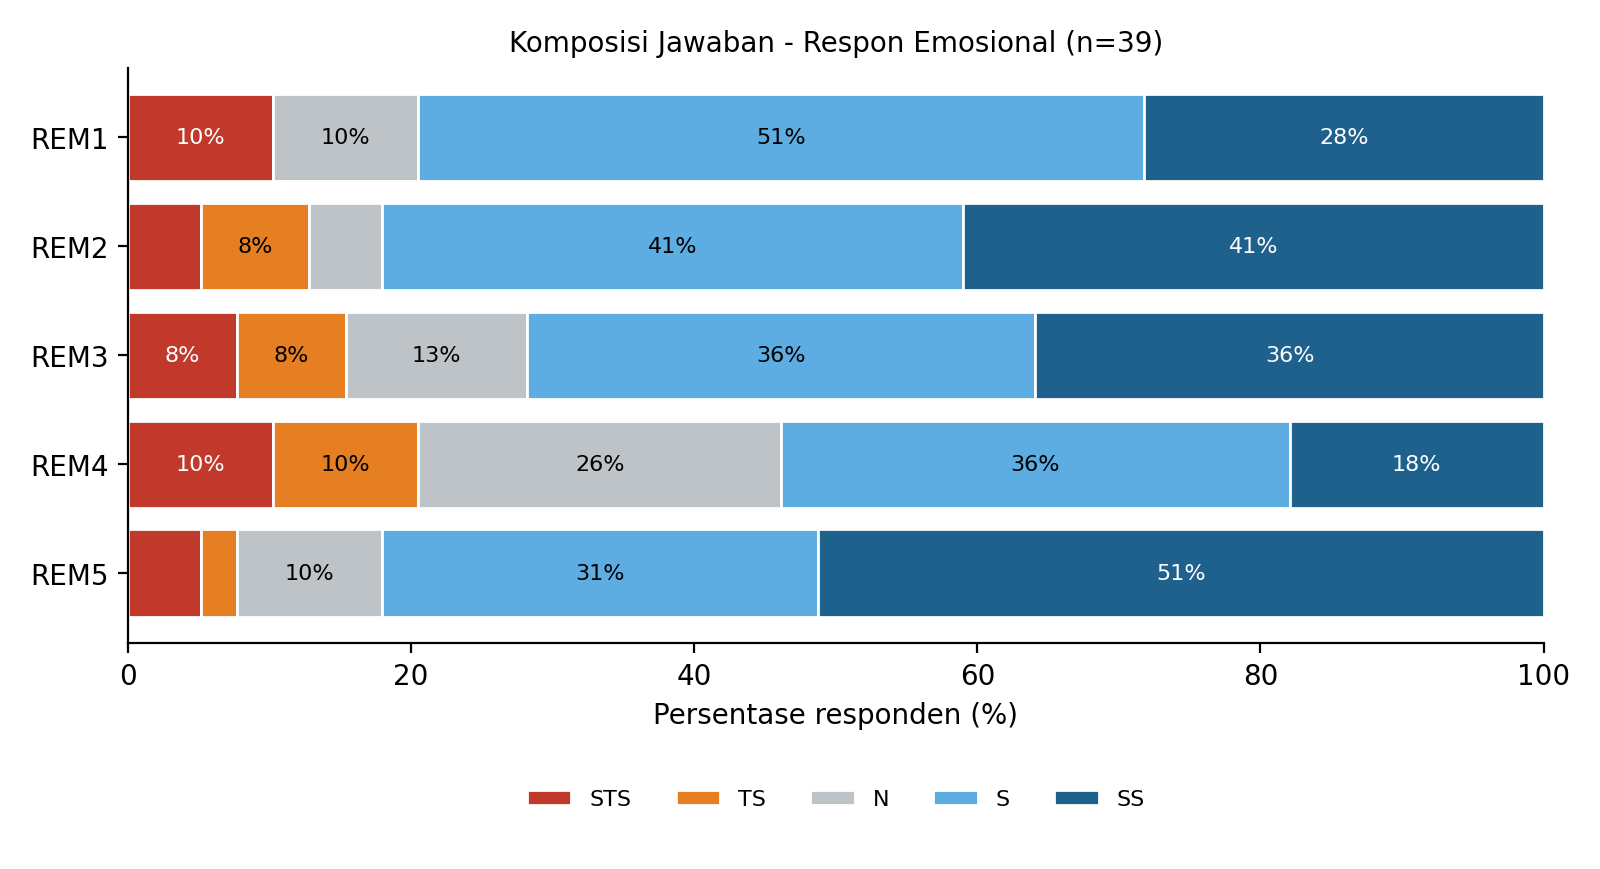

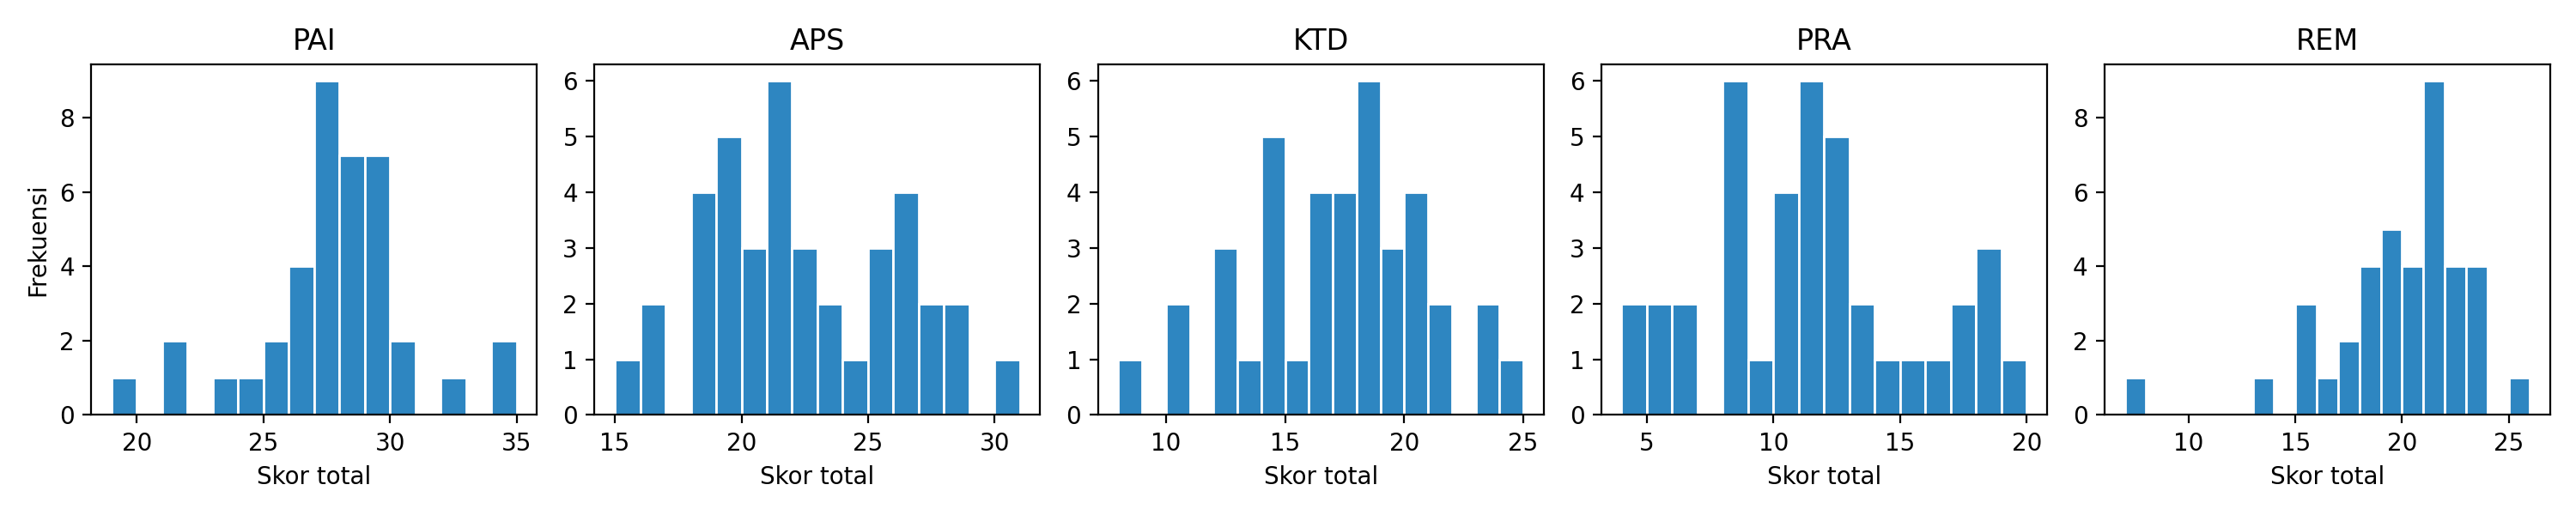

In [26]:
from IPython.display import Image, display
for kd in ['PAI','APS','KTD','PRA','REM']:
    display(Image(f'output/komposisi_{kd}.png', width=650))
display(Image('output/histogram_skor_total.png', width=900))